# Лабораторная работа 1 · Прогноз RiskScore

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn import metrics
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, LeaveOneOut, cross_val_predict
from sklearn.preprocessing import MinMaxScaler, StandardScaler

SEED = 42
folder = Path(".") if Path("train.csv").is_file() else Path("lab1")
train = pd.read_csv(folder / "train.csv")
test = pd.read_csv(folder / "test.csv")
example = pd.read_csv(folder / "ex.csv")
target = "RiskScore"
assert set(train.columns) - {target} == set(test.columns) - {"ID"}
display(pd.DataFrame({"строк": [len(train), len(test), len(example)],
                      "столбцов": [train.shape[1], test.shape[1], example.shape[1]]},
                     index=["train", "test", "ex"]))

,строк,столбцов
train,11017,35
test,5000,35
ex,5000,2


## Качество данных и разбиение

Сначала проверим, какие метки повторяются и какие поля повреждены.

In [2]:
labeled = train.dropna(subset=[target])
unique = labeled.drop_duplicates()
display(unique[target].value_counts().head(4).to_frame("частота"))
invalid = unique[target].isin([-9999999, 10000000])
clean = unique.loc[~invalid].reset_index(drop=True)
missing = pd.DataFrame({"train": clean.isna().sum(), "test": test.isna().sum()}).fillna(0)
display(missing.loc[missing.max(axis=1) > 0].astype(int))

development, control = train_test_split(clean, test_size=.20, random_state=SEED)
dev = development.dropna().reset_index(drop=True)
hold = control.dropna().reset_index(drop=True)
display(pd.Series({
    "Без метки": len(train) - len(labeled),
    "Точные дубликаты среди размеченных": len(labeled) - len(unique),
    "Повреждённые метки": invalid.sum(),
    "После очистки меток": len(clean),
    "Неполные заявки": clean.isna().any(axis=1).sum(),
    "Полные заявки для разработки": len(dev),
    "Полные заявки для итоговой проверки": len(hold),
}))
assert test.drop(columns="ID").notna().all().all()
assert set(dev.ApplicationDate).isdisjoint(hold.ApplicationDate)

,частота
RiskScore,
-9.999999e+06,121
1.000000e+07,91
6.617650e+01,1
6.266264e+01,1


,train,test
BankruptcyHistory,456,0
BaseInterestRate,456,0
CheckingAccountBalance,456,0
CreditScore,456,0
LoanAmount,456,0
LoanPurpose,456,0
MonthlyDebtPayments,456,0
NetWorth,456,0
TotalAssets,456,0


Без метки                               530
Точные дубликаты среди размеченных      487
Повреждённые метки                      212
После очистки меток                    9788
Неполные заявки                         456
Полные заявки для разработки           7464
Полные заявки для итоговой проверки    1868
dtype: int64

В тестовом файле все поля заполнены.

## Разведочный анализ

Гистограмма показывает распределение целевой переменной. На диаграммах рассеяния каждая точка соответствует одной заявке из обучающей части.

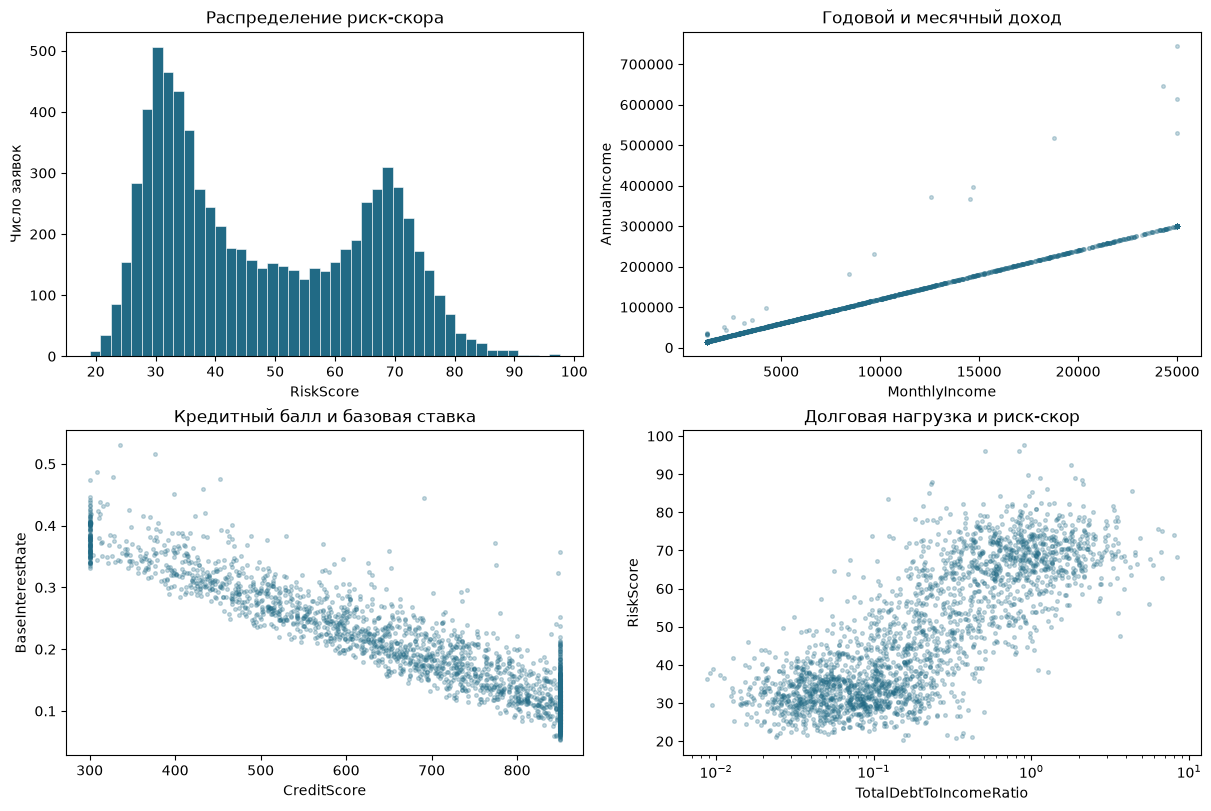

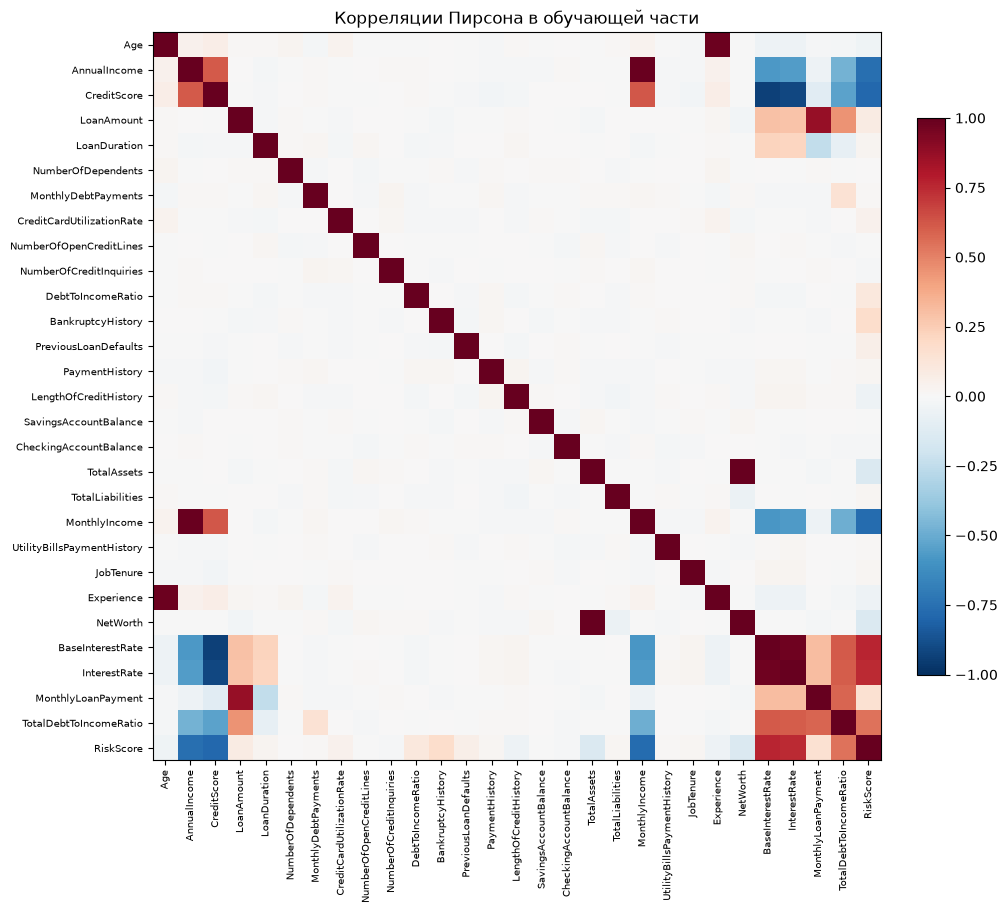

CreditScore              -0.786
MonthlyIncome            -0.770
BaseInterestRate          0.761
AnnualIncome             -0.758
InterestRate              0.745
TotalDebtToIncomeRatio    0.546
Name: RiskScore, dtype: float64

Годовой доход расходится с 12 × MonthlyIncome более чем на 1: 78


In [3]:
sample = dev.sample(min(len(dev), 2400), random_state=SEED)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
axes[0, 0].hist(dev[target], bins=45, color="#216a85", edgecolor="white", linewidth=.4)
axes[0, 0].set(xlabel="RiskScore", ylabel="Число заявок", title="Распределение риск-скора")
for ax, (x, y, title) in zip(axes.flat[1:], [
    ("MonthlyIncome", "AnnualIncome", "Годовой и месячный доход"),
    ("CreditScore", "BaseInterestRate", "Кредитный балл и базовая ставка"),
    ("TotalDebtToIncomeRatio", target, "Долговая нагрузка и риск-скор"),
]):
    ax.scatter(sample[x], sample[y], s=7, alpha=.25, color="#216a85")
    ax.set(xlabel=x, ylabel=y, title=title)
axes[1, 1].set_xscale("log")
plt.show()

cor = dev.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 9), layout="constrained")
im = ax.imshow(cor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cor)), cor.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(cor)), cor.index, fontsize=7)
ax.set_title("Корреляции Пирсона в обучающей части")
fig.colorbar(im, ax=ax, shrink=.75)
plt.show()
display(cor[target].drop(target).sort_values(key=abs, ascending=False).head(6).round(3))
print("Годовой доход расходится с 12 × MonthlyIncome более чем на 1:",
      (dev.AnnualIncome.sub(12 * dev.MonthlyIncome).abs() > 1).sum())

У риск-скора две заметные области концентрации, около 30 и 70. На диаграмме нагрузки особенно велик разброс при промежуточных значениях. Кредитный балл и доход связаны с риском отрицательно, ставка и общая долговая нагрузка — положительно. Эти связи описывают выборку и сами по себе не устанавливают причинность.

Большинство заявок лежит на прямой `AnnualIncome = 12 × MonthlyIncome`, но видны отклонения. В признаках используем доход, пересчитанный из месячного. На графике ставки также видна сильная зависимость от кредитного балла. Это мотивирует сравнение обычного МНК с регуляризацией.

## Четыре метрики

Для ошибок $e_i=y_i-\hat y_i$ вычисляем $\mathrm{MSE}=\overline{e^2}$, $\mathrm{MAE}=\overline{|e|}$ и $R^2=1-\sum e_i^2/\sum(y_i-\bar y)^2$. MAPE усредняет $|e_i|/|y_i|$. Функция возвращает долю, как в sklearn, а таблицы выводят проценты. Для нулевого знаменателя MAPE используем машинный эпсилон.

In [4]:
def mse(y, pred):
    return np.mean((np.asarray(y) - np.asarray(pred)) ** 2)

def mae(y, pred):
    return np.mean(np.abs(np.asarray(y) - np.asarray(pred)))

def r2(y, pred):
    y = np.asarray(y)
    residual = np.sum((y - pred) ** 2)
    total = np.sum((y - y.mean()) ** 2)
    return 1 - residual / total if total > 0 else float(residual == 0)

def mape(y, pred):
    y = np.asarray(y, dtype=float)
    return np.mean(np.abs(y - pred) / np.maximum(np.abs(y), np.finfo(float).eps))

def report(y, pred):
    return {"MSE": mse(y, pred), "MAE": mae(y, pred),
            "R²": r2(y, pred), "MAPE, %": 100 * mape(y, pred)}

def compare_metrics(y, pred):
    actual = list(report(y, pred).values())
    reference = [metrics.mean_squared_error(y, pred), metrics.mean_absolute_error(y, pred),
                 metrics.r2_score(y, pred), 100 * metrics.mean_absolute_percentage_error(y, pred)]
    np.testing.assert_allclose(actual, reference)
    return pd.DataFrame({"Реализация": actual, "sklearn": reference},
                        index=report(y, pred).keys())

y_check = np.array([2., 4., 6.])
pred_check = np.array([3., 2., 5.])
np.testing.assert_allclose(list(report(y_check, pred_check).values()),
                           [2., 4/3, .25, 100 * 7/18])
display(compare_metrics(y_check, pred_check))

,Реализация,sklearn
MSE,2.000000,2.000000
MAE,1.333333,1.333333
R²,0.250000,0.250000
"MAPE, %",38.888889,38.888889


## Нормализация

Для z-score вычитаем среднее и делим на стандартное отклонение с $ddof=0$. Для min-max вычитаем минимум и делим на размах. Параметры определяет только обучающая часть текущего разбиения. Постоянному столбцу задаём делитель 1.

In [5]:
class Scaler:
    def __init__(self, method="zscore"):
        self.method = method

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if self.method == "zscore":
            self.offset_, scale = X.mean(axis=0), X.std(axis=0)
        elif self.method == "minmax":
            self.offset_, scale = X.min(axis=0), np.ptp(X, axis=0)
        else:
            raise ValueError("method: zscore или minmax")
        self.scale_ = np.where(scale == 0, 1., scale)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.offset_) / self.scale_

tiny = np.array([[1., 7.], [2., 7.], [5., 7.]])
unseen = np.array([[7., 7.]])
for method, ref in [("zscore", StandardScaler()), ("minmax", MinMaxScaler())]:
    scaler = Scaler(method).fit(tiny)
    np.testing.assert_allclose(scaler.transform(unseen), ref.fit(tiny).transform(unseen))
    print(method, scaler.transform(tiny).round(3).tolist())

zscore [[-0.981, 0.0], [-0.392, 0.0], [1.373, 0.0]]
minmax [[0.0, 0.0], [0.25, 0.0], [1.0, 0.0]]


## Три способа обучить линейную регрессию

Предсказание равно $b+x^Tw$. Центрируем $X$ и $y$, после обучения восстанавливаем свободный член $b=\bar y-\bar x^Tw$. Для центрированной матрицы $A$ аналитическое решение МНК равно $w=A^+(y-\bar y)$. `lstsq` вычисляет это решение и при линейно зависимых столбцах.

Для функции потерь $\|Aw-y_c\|^2/(2n)$ градиент равен $A^T(Aw-y_c)/n$. Полный градиентный спуск делает шаг по всем строкам. SGD перемешивает строки каждую эпоху и обновляет веса после одного наблюдения с убывающей длиной шага.

In [6]:
class LinearRegressor:
    def __init__(self, solver="analytic", epochs=150, rate=.02, seed=SEED, alpha=0.):
        self.solver, self.epochs, self.rate = solver, epochs, rate
        self.seed, self.alpha = seed, alpha

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        A, yc = X - X.mean(axis=0), y - y.mean()
        n, d = A.shape
        if self.alpha < 0 or (self.alpha and self.solver != "analytic"):
            raise ValueError("Для L2 используйте analytic и alpha >= 0")
        if self.solver == "analytic":
            if self.alpha:
                # Добавочные строки дают штраф alpha * ||w||² / 2.
                A = np.vstack([A, np.sqrt(n * self.alpha) * np.eye(d)])
                yc = np.r_[yc, np.zeros(d)]
            w = np.linalg.lstsq(A, yc, rcond=None)[0]
        elif self.solver == "gd":
            w = np.zeros(d)
            step = n / max(np.linalg.norm(A, ord=2) ** 2, 1.)
            for _ in range(self.epochs):
                w -= step * (A.T @ (A @ w - yc) / n)
        elif self.solver == "sgd":
            w = np.zeros(d)
            rng = np.random.default_rng(self.seed)
            updates = 0
            for _ in range(self.epochs):
                for i in rng.permutation(n):
                    eta = self.rate / (1 + updates / n)
                    w -= eta * (A[i] @ w - yc[i]) * A[i]
                    updates += 1
        else:
            raise ValueError("solver: analytic, gd или sgd")
        self.coef_, self.intercept_ = w, y.mean() - X.mean(axis=0) @ w
        return self

    def predict(self, X):
        return self.intercept_ + np.asarray(X) @ self.coef_

Сравним способы оптимизации на одном подмножестве признаков. Здесь цель — проверить реализацию. Все методы видят одни и те же строки и признаки. Внутренняя проверка взята из части для разработки.

In [7]:
a, b = train_test_split(dev, test_size=.25, random_state=17)
demo_cols = ["CreditScore", "MonthlyIncome", "DebtToIncomeRatio",
             "BankruptcyHistory", "CreditCardUtilizationRate", "LengthOfCreditHistory"]
scaler = Scaler().fit(a[demo_cols])
Xa, Xb = scaler.transform(a[demo_cols]), scaler.transform(b[demo_cols])
ya, yb = a[target].to_numpy(), b[target].to_numpy()

solvers = {
    "МНК, аналитически": LinearRegressor(),
    "Полный GD": LinearRegressor("gd", epochs=300),
    "Построчный SGD": LinearRegressor("sgd", epochs=90),
    "sklearn LinearRegression": LinearRegression(),
    "sklearn SGDRegressor": SGDRegressor(penalty=None, max_iter=200, tol=None,
                                         eta0=.01, learning_rate="invscaling", random_state=SEED),
}
preds = {name: model.fit(Xa, ya).predict(Xb) for name, model in solvers.items()}
display(pd.DataFrame({k: report(yb, v) for k, v in preds.items()}).T.round(4))
np.testing.assert_allclose(preds["МНК, аналитически"], preds["sklearn LinearRegression"], atol=1e-8)
np.testing.assert_allclose(preds["Полный GD"], preds["МНК, аналитически"], atol=1e-6)
print("Среднее расхождение SGD с МНК:", round(mae(preds["МНК, аналитически"], preds["Построчный SGD"]), 4))

,MSE,MAE,R²,"MAPE, %"
"МНК, аналитически",59.8302,6.2129,0.8015,14.7305
Полный GD,59.8302,6.2129,0.8015,14.7305
Построчный SGD,59.8435,6.2133,0.8015,14.7320
sklearn LinearRegression,59.8302,6.2129,0.8015,14.7305
sklearn SGDRegressor,59.8195,6.2120,0.8016,14.7407


Среднее расхождение SGD с МНК: 0.0246


## Регуляризация L1, L2, L1+L2 и Lp

Решаем задачу $\|Aw-y_c\|^2/(2n)+\lambda_1\|w\|_1+\lambda_p\sum_j |w_j|^p/p$, где $p\geq 1$. L1 может занулять коэффициенты, L2 плавно уменьшает их величину. При $p=2$ и двух ненулевых штрафах получаем Elastic Net. Свободный член исключён из штрафа.

После шага по градиенту квадратичной потери применяем мягкое пороговое преобразование для L1. Для остатка $v$ модуль нового коэффициента решает $u+t\lambda_p u^{p-1}=v$. При $p=2$ решение аналитическое, при других $p>1$ используем бисекцию на $[0,v]$.

In [8]:
class PenalizedRegression:
    def __init__(self, l1=0., lp=0., p=2., tol=1e-9, max_iter=3000):
        if min(l1, lp) < 0 or not np.isfinite(p) or p < 1:
            raise ValueError("Штрафы должны быть неотрицательными, p >= 1")
        self.l1, self.lp, self.p = l1, lp, p
        self.tol, self.max_iter = tol, max_iter

    def prox(self, v, step):
        threshold = self.l1 + (self.lp if self.p == 1 else 0.)
        size = np.maximum(np.abs(v) - step * threshold, 0.)
        if self.lp and self.p == 2:
            size /= 1 + step * self.lp
        elif self.lp and self.p > 1:
            lo, hi = np.zeros_like(size), size.copy()
            for _ in range(45):
                mid = (lo + hi) / 2
                lower = mid + step * self.lp * mid ** (self.p - 1) < size
                lo, hi = np.where(lower, mid, lo), np.where(lower, hi, mid)
            size = (lo + hi) / 2
        return np.sign(v) * size

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        A = X - X.mean(axis=0)
        gram = A.T @ A / len(X)
        rhs = A.T @ (y - y.mean()) / len(X)
        step = 1 / max(np.linalg.eigvalsh(gram)[-1], 1e-12)
        w = np.zeros(X.shape[1])
        for _ in range(self.max_iter):
            new = self.prox(w - step * (gram @ w - rhs), step)
            if np.max(np.abs(new - w)) < self.tol:
                w = new
                break
            w = new
        self.coef_, self.intercept_ = w, y.mean() - X.mean(axis=0) @ w
        return self

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

strength = .15
pairs = [
    ("L1", PenalizedRegression(l1=strength), Lasso(alpha=strength, tol=1e-10)),
    ("L2", PenalizedRegression(lp=strength), Ridge(alpha=len(ya)*strength)),
    ("L1 + L2", PenalizedRegression(l1=.4*strength, lp=.6*strength),
     ElasticNet(alpha=strength, l1_ratio=.4, tol=1e-10)),
]
rows = []
for name, model, reference in pairs:
    pred = model.fit(Xa, ya).predict(Xb)
    ref = reference.fit(Xa, ya).predict(Xb)
    np.testing.assert_allclose(pred, ref, atol=1e-6)
    rows.append({"Штраф": name, "MSE": mse(yb, pred), "MSE sklearn": mse(yb, ref),
                 "max |разница прогнозов|": np.abs(pred-ref).max()})

p_user = 1.5   # Можно изменить порядок штрафа на любое p >= 1.
model_lp = PenalizedRegression(lp=strength, p=p_user).fit(Xa, ya)
w = model_lp.coef_
gradient = (Xa - Xa.mean(axis=0)).T @ (model_lp.predict(Xa) - ya) / len(ya)
if p_user > 1:
    grad_penalty = strength * np.sign(w) * np.abs(w) ** (p_user - 1)
    assert np.linalg.norm(gradient + grad_penalty, ord=np.inf) < 1e-5
else:
    active = np.abs(w) > 1e-8
    assert np.all(np.abs(gradient[~active]) <= strength + 1e-6)
    np.testing.assert_allclose(gradient[active], -strength * np.sign(w[active]), atol=1e-5)
display(pd.DataFrame(rows).set_index("Штраф"))
print(f"Lp, p={p_user:g}, MSE = {mse(yb, model_lp.predict(Xb)):.4f}")

,MSE,MSE sklearn,max |разница прогнозов|
Штраф,,,
L1,59.926147,59.926147,1.047145e-08
L2,61.978842,61.978842,5.896595e-09
L1 + L2,60.902113,60.902113,6.722587e-09


Lp, p=1.5, MSE = 60.2675


## Признаки для итоговой модели

Сравниваем три представления одних и тех же заявок. Первое кодирует диапазоны дохода, кредитного балла, долговой нагрузки, капитала и длины кредитной истории. Например, при балле 710 активны индикаторы порогов 600, 650 и 700. МНК оценивает вклад каждого перехода.

Во втором представлении добавляем составной показатель `balance`. В нём доход и капитал увеличивают доступный запас средств, а сумма кредита, срок и долговая нагрузка уменьшают его. Денежные масштабы, веса и границы — эмпирические параметры признаков этого эксперимента. Они подобраны на части для разработки. Показатель не интерпретируется как вероятность дефолта.

Плавные функции от показателя и произведения с индикаторами позволяют в разных диапазонах долговой нагрузки по-разному учитывать один и тот же признак. Третье представление добавляет поправки в переходной области, где произведение `gate × (1 − gate)` максимально. При предсказании все эти столбцы вычисляются только из полей заявки. По готовым столбцам прогноз по-прежнему имеет вид $b+\sum_j w_j x_j$.

In [9]:
def risk_features(data, variant="balance"):
    income = 12 * data["MonthlyIncome"]
    debt = data["TotalDebtToIncomeRatio"]
    education = data["EducationLevel"].map({
        "High School": 0, "Associate": 1, "Bachelor": 2, "Master": 3, "Doctorate": 4
    })
    self_employed = data["EmploymentStatus"].eq("Self-Employed").astype(float)
    unemployed = data["EmploymentStatus"].eq("Unemployed").astype(float)

    bands = {
        "CreditScore": [600, 650, 700, 750],
        "MonthlyIncome": np.array([30000, 50000, 80000, 120000]) / 12,
        "NetWorth": [50000, 100000, 250000, 500000, 1000000],
        "DebtToIncomeRatio": [.2, .3, .4, .5],
        "LengthOfCreditHistory": [3, 5, 7, 10],
        "CreditCardUtilizationRate": [.2, .4, .6, .8],
    }
    columns, band_counts = {}, {}
    for name, cuts in bands.items():
        flags = data[name].to_numpy()[:, None] >= cuts
        band_counts[name] = flags.sum(axis=1)
        for i, flag in enumerate(flags.T):
            columns[f"{name}_band_{i+1}"] = flag
    history = {
        "BankruptcyHistory": data["BankruptcyHistory"],
        "PreviousLoanDefaults": data["PreviousLoanDefaults"],
        "SelfEmployed": self_employed,
        "Unemployed": unemployed,
    }
    base = pd.DataFrame({**columns, **history}, index=data.index, dtype=float)
    if variant == "bands":
        return base

    resources = (income / 200000 + data["NetWorth"] / 1000000
                 - data["LoanAmount"] / 100000)
    credit_terms = (data["LoanDuration"] / 200
                    + 5 * (data["InterestRate"] - data["BaseInterestRate"]))
    track_record = (.007 * data["LengthOfCreditHistory"] + .06 * education
                    - .30 * data["BankruptcyHistory"] - .15 * data["PreviousLoanDefaults"]
                    - .10 * unemployed + .08 * data["Age"].between(30, 55))
    burden = .5 * debt + .2 * np.log(debt / .3)
    balance = resources + track_record - credit_terms - burden
    gate = 1 / (1 + np.exp(-np.clip(7 * (balance - .2), -50, 50)))
    groups = pd.DataFrame({**band_counts, **history}, index=data.index)
    interactions = groups.mul(gate, axis=0).add_suffix("_by_balance")
    curves = pd.DataFrame({f"balance_{k}": np.tanh(4 * (balance - k))
                           for k in [-.6, -.3, 0, .3, .6, .9]})
    if variant == "balance":
        return pd.concat([base, curves, interactions], axis=1)

    local = data[["PaymentHistory", "CreditScore", "InterestRate", "LengthOfCreditHistory",
                  "MonthlyIncome", "LoanAmount", "NetWorth", "TotalDebtToIncomeRatio",
                  "LoanDuration"]].copy()
    local["distance_age_40"] = (data["Age"] - 40).abs()
    local["log_debt"] = np.log(debt)
    local["log_loan"] = np.log(data["LoanAmount"])
    local["log_income"] = np.log(income)
    local["loan_to_income"] = data["LoanAmount"] / income
    local["education"] = education
    local["own_home"] = data["HomeOwnershipStatus"].eq("Own")
    local["experience_under_20"] = (data["Experience"] - 20).clip(upper=0)
    local["card_utilization"] = data["CreditCardUtilizationRate"]
    local["self_employed"] = self_employed
    local["debt_consolidation"] = data["LoanPurpose"].eq("Debt Consolidation")
    local["doctorate"] = data["EducationLevel"].eq("Doctorate")
    local["age_under_25"] = data["Age"].lt(25)
    local["age_over_55"] = data["Age"].gt(55)
    local = local.mul(gate * (1 - gate), axis=0).add_suffix("_by_transition")
    return pd.concat([base, curves, interactions, local], axis=1)

## Кросс-валидация

**K-fold.** Один раз перемешиваем индексы и разбиваем их на $k$ непересекающихся групп. Каждая строка ровно один раз получает прогноз модели, обученной на остальных группах. Считаем MSE по всем этим прогнозам и показываем разброс по фолдам.

**Leave-one-out.** При $k=n$ оставляем для проверки одну строку. Ниже есть явное переобучение для каждого исключения и быстрая проверка для полного МНК. Для матрицы с константой $A=U\Sigma V^T$ проекционная матрица равна $H=U_r U_r^T$, где $r$ — численный ранг. Если $e_i$ — остаток полной модели, то остаток при исключении строки равен $e_i/(1-h_{ii})$. Вычисляем только диагональ $H$. Формула применяется к фиксированным признакам без регуляризации.

In [10]:
def kfold_indices(n, k=5, seed=SEED):
    if not 2 <= k <= n:
        raise ValueError("Требуется 2 <= k <= n")
    groups = np.array_split(np.random.default_rng(seed).permutation(n), k)
    for i, valid in enumerate(groups):
        yield np.concatenate(groups[:i] + groups[i+1:]), valid

def loo_indices(n):
    if n < 2:
        raise ValueError("Требуются минимум два наблюдения")
    indices = np.arange(n)
    for i in indices:
        yield np.concatenate([indices[:i], indices[i+1:]]), indices[i:i+1]

def oof_predict(X, y, splits, alpha=0.):
    X, y = np.asarray(X), np.asarray(y)
    out = np.empty(len(y))
    scores = []
    for tr, va in splits:
        scale = Scaler().fit(X[tr])
        reg = LinearRegressor(alpha=alpha).fit(scale.transform(X[tr]), y[tr])
        out[va] = reg.predict(scale.transform(X[va]))
        scores.append(mse(y[va], out[va]))
    return out, scores

def loo_ols(X, y):
    X, y = np.asarray(X), np.asarray(y)
    # Масштабирование обратимо для непостоянных столбцов и не меняет прогноз МНК.
    A = np.column_stack([np.ones(len(X)), Scaler().fit(X).transform(X)])
    U, singular, _ = np.linalg.svd(A, full_matrices=False)
    keep = singular > singular.max() * max(A.shape) * np.finfo(float).eps
    basis = U[:, keep]
    leverage = np.sum(basis ** 2, axis=1)
    if np.any(1 - leverage < 1e-10):
        return oof_predict(X, y, loo_indices(len(y)))[0]
    fitted = basis @ (basis.T @ y)
    return y - (y - fitted) / (1 - leverage)

small_x, small_y = Xa[:60], ya[:60]
direct, _ = oof_predict(small_x, small_y, loo_indices(len(small_y)))
fast = loo_ols(small_x, small_y)
sk_loo = cross_val_predict(LinearRegression(), small_x, small_y, cv=LeaveOneOut())
np.testing.assert_allclose(direct, sk_loo, atol=1e-8)
np.testing.assert_allclose(fast, direct, atol=1e-8)
folds = list(kfold_indices(len(dev), k=5))
np.testing.assert_array_equal(np.sort(np.concatenate([va for _, va in folds])), np.arange(len(dev)))
assert all(len(np.intersect1d(tr, va)) == 0 for tr, va in folds)
print(f"LOO на 60 строках: MSE = {mse(small_y, direct):.4f}, "
      f"max |PRESS − перебор| = {np.abs(fast-direct).max():.2e}")

LOO на 60 строках: MSE = 72.1017, max |PRESS − перебор| = 7.82e-14


### Выбор признаков и силы L2

Базовый ориентир — обычная линейная регрессия на исходных числовых признаках. Для всех вариантов используем одинаковые фолды. В столбце «MSE OOF» каждая заявка имеет одинаковый вес. По этому столбцу выбираем модель до обращения к контрольной части.

In [11]:
numeric_cols = dev.select_dtypes(include="number").columns.drop(target)
def design(data, variant):
    if variant == "numeric":
        return data[numeric_cols]
    return risk_features(data, variant)

y_dev = dev[target].to_numpy()
results, scores_by_model = [], {}
for variant in ["numeric", "bands", "balance", "full"]:
    X = design(dev, variant)
    strengths = [0., .001, .005] if variant == "full" else [0.]
    for alpha in strengths:
        oof, fold_scores = oof_predict(X, y_dev, folds, alpha=alpha)
        results.append({"Признаки": variant, "alpha": alpha, "Столбцов": X.shape[1],
                        "MSE OOF": mse(y_dev, oof), "SD фолдов": np.std(fold_scores)})
        scores_by_model[(variant, alpha)] = fold_scores

ranking = pd.DataFrame(results).sort_values("MSE OOF").reset_index(drop=True)
display(ranking.round(4))
best = ranking.iloc[0]
variant, alpha = best["Признаки"], float(best["alpha"])
print("MSE по фолдам выбранного варианта:",
      np.round(scores_by_model[(variant, alpha)], 3))
X_dev = design(dev, variant)
loo = loo_ols(X_dev, y_dev)
print(f"Leave-one-out для МНК на этих признаках: MSE = {mse(y_dev, loo):.4f}")

,Признаки,alpha,Столбцов,MSE OOF,SD фолдов
0,full,0.005,68,18.1385,0.9114
1,full,0.001,68,18.1469,0.9678
2,full,0.000,68,18.1984,0.9894
3,balance,0.000,45,18.4738,0.7599
4,bands,0.000,29,30.6454,1.3234
5,numeric,0.000,28,50.7435,2.8966


MSE по фолдам выбранного варианта: [19.211 17.627 17.466 19.262 17.126]
Leave-one-out для МНК на этих признаках: MSE = 18.1466


## Контрольная выборка

Переобучаем выбранную конфигурацию на части для разработки. Контрольные строки впервые участвуют в расчёте метрик. На графике ниже линия соответствует точному прогнозу, а расстояния до линии показывают направление и величину ошибок.

,Реализация,sklearn
MSE,18.77229,18.77229
MAE,3.00011,3.00011
R²,0.93840,0.93840
"MAPE, %",6.88051,6.88051


Модель: full, alpha=0.005. Порог 19 на контроле: пройден


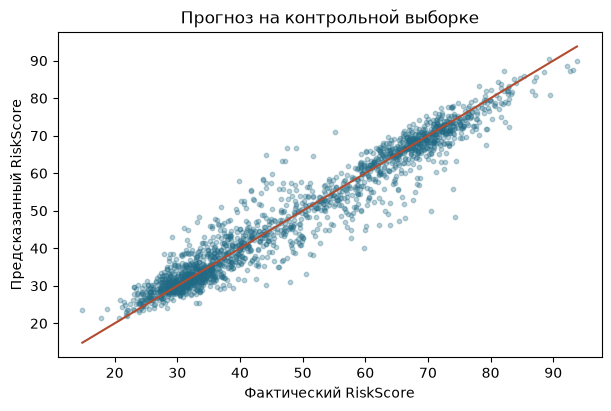

In [12]:
def fit_predict(data, new_data, variant, alpha):
    X = design(data, variant)
    new_X = design(new_data, variant)
    assert X.columns.equals(new_X.columns)
    scale = Scaler().fit(X)
    reg = LinearRegressor(alpha=alpha).fit(scale.transform(X), data[target].to_numpy())
    return reg.predict(scale.transform(new_X))

pred = fit_predict(dev, hold, variant, alpha)
y_hold = hold[target].to_numpy()
display(compare_metrics(y_hold, pred).round(5))
print(f"Модель: {variant}, alpha={alpha:g}. Порог 19 на контроле:",
      "пройден" if mse(y_hold, pred) < 19 else "превышен")
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.scatter(y_hold, pred, alpha=.3, s=10, color="#216a85")
lo, hi = min(y_hold.min(), pred.min()), max(y_hold.max(), pred.max())
ax.plot([lo, hi], [lo, hi], color="#b24c30", lw=1.5)
ax.set(xlabel="Фактический RiskScore", ylabel="Предсказанный RiskScore",
       title="Прогноз на контрольной выборке")
plt.show()

### Вывод

На одних и тех же пяти фолдах переход от исходных числовых признаков к диапазонам снизил MSE с 50,74 до 30,65. При добавлении составного показателя и взаимодействий лучшую среднюю ошибку дала линейная регрессия с L2 и $\alpha=0{,}005$ — **18,14**. В двух из пяти фолдов MSE превысила 19.

На отдельной контрольной выборке из 1 868 полных заявок получены **MSE 18,77**, MAE 3,00, $R^2$ 0,938 и MAPE 6,88 %. В среднем абсолютное отклонение прогноза составляет около трёх баллов RiskScore. Запас до порога на этой выборке составляет 0,23 MSE.

## Файл для Kaggle

Теперь используем все полные заявки с корректной меткой, включая контрольную часть. Порядок строк и идентификаторы берём из `test.csv`. Файл `ex.csv` определяет схему посылки. Его значения риск-скора не используются в обучении.

In [13]:
all_rows = clean.dropna().reset_index(drop=True)
test_pred = fit_predict(all_rows, test, variant, alpha)
submission = test[["ID"]].assign(RiskScore=test_pred)
assert list(submission.columns) == list(example.columns) == ["ID", "RiskScore"]
assert submission.ID.is_unique and submission.ID.equals(test.ID)
assert set(submission.ID) == set(example.ID)
assert len(submission) == len(test) and np.isfinite(test_pred).all()
path = folder / "submission.csv"
submission.to_csv(path, index=False)
saved = pd.read_csv(path)
pd.testing.assert_frame_equal(saved, submission, check_exact=False, rtol=1e-12)
print(f"{path.name}: {len(saved)} строк, {len(all_rows)} заявок в финальном обучении.")
display(saved.head())

submission.csv: 5000 строк, 9332 заявок в финальном обучении.


,ID,RiskScore
0,0,32.765227
1,1,53.428041
2,2,30.037704
3,3,34.806596
4,4,33.501690


Локальный результат оценивает качество на заявках из размеченного файла. Официальную MSE на скрытых метках `test.csv` рассчитывает Kaggle после отправки `submission.csv`.